In [1]:
import pandas as pd
import matplotlib.pyplot as plt 
from sklearn.preprocessing import StandardScaler

In [2]:
datas =pd.read_csv('data/penguins.csv',sep=',')
datas.isnull().sum()

culmen_length_mm     2
culmen_depth_mm      2
flipper_length_mm    2
body_mass_g          2
sex                  9
dtype: int64

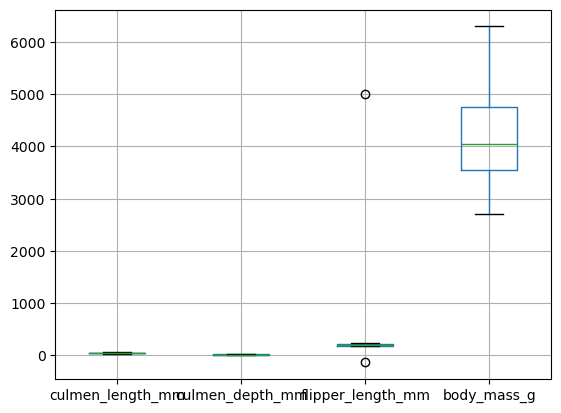

In [3]:
datas.boxplot()
plt.show()

In [4]:
df = datas.dropna()
df.isna().sum()

culmen_length_mm     0
culmen_depth_mm      0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64

In [6]:
df = df.loc[(df['flipper_length_mm']<4000) & (df['flipper_length_mm']>0)]
df.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
4,36.7,19.3,193.0,3450.0,FEMALE
5,39.3,20.6,190.0,3650.0,MALE


In [7]:
df = pd.get_dummies(df)
df.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex_.,sex_FEMALE,sex_MALE
0,39.1,18.7,181.0,3750.0,False,False,True
1,39.5,17.4,186.0,3800.0,False,True,False
2,40.3,18.0,195.0,3250.0,False,True,False
4,36.7,19.3,193.0,3450.0,False,True,False
5,39.3,20.6,190.0,3650.0,False,False,True


In [8]:
df = df.drop('sex_.',axis=1)
df.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex_FEMALE,sex_MALE
0,39.1,18.7,181.0,3750.0,False,True
1,39.5,17.4,186.0,3800.0,True,False
2,40.3,18.0,195.0,3250.0,True,False
4,36.7,19.3,193.0,3450.0,True,False
5,39.3,20.6,190.0,3650.0,False,True


In [9]:
scaler = StandardScaler()
df_scaler = scaler.fit_transform(df)
df_scaler[:5]


array([[-0.90552018,  0.79312591, -1.42812496, -0.56970896, -0.99103121,
         0.99700149],
       [-0.83193838,  0.12850298, -1.07152207, -0.50757924,  1.00904996,
        -1.00300753],
       [-0.68477478,  0.43525202, -0.42963687, -1.1910061 ,  1.00904996,
        -1.00300753],
       [-1.34701098,  1.09987495, -0.57227803, -0.94248724,  1.00904996,
        -1.00300753],
       [-0.86872928,  1.76449788, -0.78623976, -0.69396839, -0.99103121,
         0.99700149]])

In [12]:
df_scaler = pd.DataFrame(df_scaler,columns=df.columns)
df_scaler.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex_FEMALE,sex_MALE
0,-0.905520,0.793126,-1.428125,-0.569709,-0.991031,0.997001
1,-0.831938,0.128503,-1.071522,-0.507579,1.009050,-1.003008
2,-0.684775,0.435252,-0.429637,-1.191006,1.009050,-1.003008
3,-1.347011,1.099875,-0.572278,-0.942487,1.009050,-1.003008
4,-0.868729,1.764498,-0.786240,-0.693968,-0.991031,0.997001


In [14]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_samples

In [15]:
sc = []
inertia = []
for i in range (2,9):
    kmeans = KMeans(n_clusters=i,n_init=10,random_state=151).fit(df_scaler)
    sc_data = silhouette_samples(df_scaler,kmeans.labels_)
    sc.append(sc_data)
    inertia.append(kmeans.inertia_)

d:\Anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
d:\Anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
d:\Anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
d:\Anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than avai

<Figure size 1000x300 with 0 Axes>

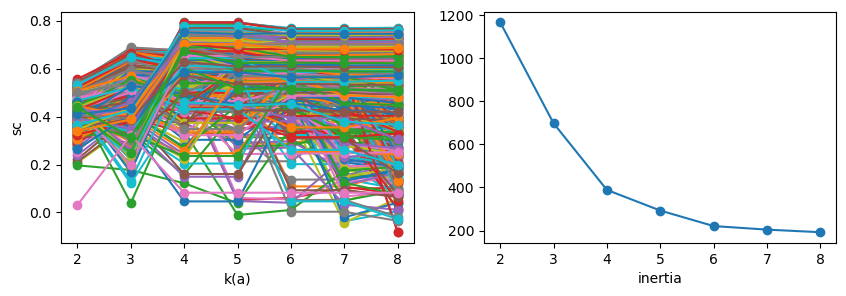

In [17]:
plt.figure(figsize=(10,3))
ax1 = plt.subplot(121)
plt.plot(range(2,9),sc,marker='o')
ax1.set_xlabel('k(a)')
ax1.set_ylabel('sc')
ax2 = plt.subplot(122)
plt.plot(range(2,9),inertia,marker='o')
ax2.set_xlabel('k(b)')
ax2.set_xlabel('inertia')
plt.show()

In [18]:
kmeans4 = KMeans(n_clusters=4,random_state=151).fit(df_scaler)

d:\Anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


In [20]:
kmeans4.labels_

array([2, 1, 1, 1, 2, 1, 2, 1, 2, 1, 1, 2, 1, 2, 1, 2, 1, 2, 2, 1, 2, 1,
       1, 2, 1, 2, 1, 2, 1, 2, 2, 1, 1, 2, 1, 2, 1, 2, 1, 2, 2, 1, 2, 1,
       2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1,
       2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 2, 1, 2, 1, 1, 2, 1, 2, 1,
       2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1,
       2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1,
       2, 1, 2, 1, 2, 1, 2, 2, 1, 1, 2, 1, 2, 1, 2, 2, 1, 2, 1, 1, 2, 1,
       2, 1, 2, 1, 2, 1, 2, 2, 1, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1,
       2, 1, 2, 2, 1, 1, 2, 1, 2, 2, 1, 2, 1, 1, 2, 1, 2, 2, 1, 1, 2, 1,
       2, 1, 2, 1, 2, 2, 1, 2, 1, 1, 2, 1, 2, 2, 1, 3, 0, 3, 0, 0, 3, 3,
       0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 0, 3, 3, 0, 3, 0, 0, 3, 0,
       0, 3, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 0, 3, 3, 0, 3, 0, 3, 0,
       3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 0, 3, 0, 3, 0, 0, 3, 3,
       0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0,

In [21]:
kmeans4.cluster_centers_

array([[ 1.0027816 , -0.73140008,  1.46328141,  1.58598843, -0.99103121,
         0.99700149],
       [-0.69990374,  0.23648629, -0.8542276 , -0.98081025,  1.00904996,
        -1.00300753],
       [-0.02653004,  1.00341299, -0.44645776, -0.25085457, -0.99103121,
         0.99700149],
       [ 0.28020689, -1.47543058,  0.83841882,  0.5896947 ,  0.97515028,
        -1.00300753]])

d:\Anaconda3\Lib\site-packages\seaborn\axisgrid.py:123: UserWarning: Glyph 46 (.) missing from font(s) SimHei.
  self._figure.tight_layout(*args, **kwargs)
d:\Anaconda3\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 45 (-) missing from font(s) SimHei.
  fig.canvas.draw()
d:\Anaconda3\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 46 (.) missing from font(s) SimHei.
  fig.canvas.draw()
d:\Anaconda3\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 29289 (\N{CJK UNIFIED IDEOGRAPH-7269}) missing from font(s) SimHei.
  fig.canvas.draw()
d:\Anaconda3\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 31181 (\N{CJK UNIFIED IDEOGRAPH-79CD}) missing from font(s) SimHei.
  fig.canvas.draw()
d:\Anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 45 (-) missing from font(s) SimHei.
  fig.canvas.print_figure(bytes_io, **kw)
d:\Anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 46 (.) missing from font(s) Si

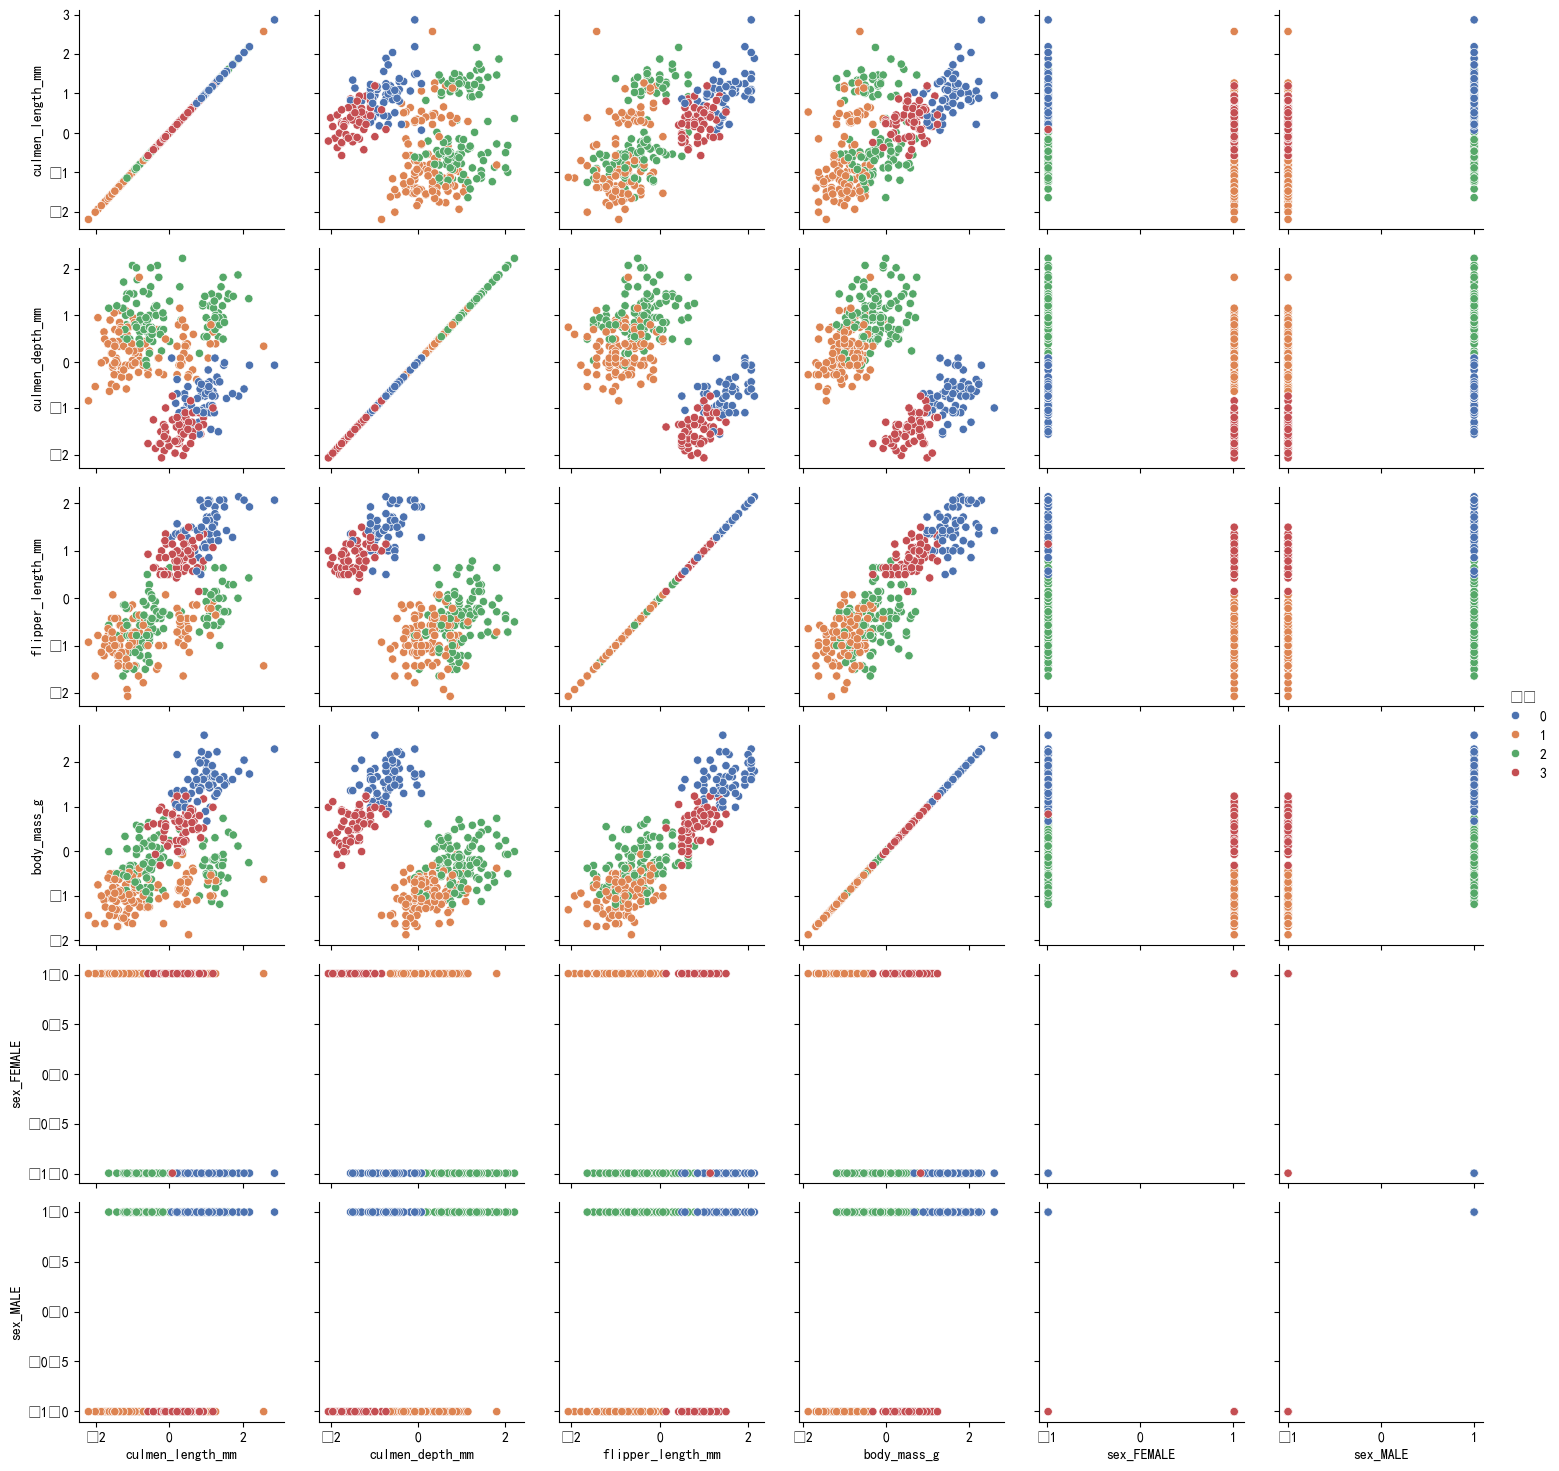

In [22]:
import seaborn as sns
df_scaler['物种'] = kmeans4.labels_
plt.rcParams['font.family'] = 'SimHei'
plt.rcParams['axes.unicode_minus'] = False
g = sns.PairGrid(df_scaler,hue='物种',palette='deep')
g.map(sns.scatterplot)
g.add_legend()
plt.show()